**[Course Home](../README.md) | [Conceptual Track](../conceptual/04_mutual_information_and_venn_geometry.ipynb) | [Prev: Ch 03: Relative Entropy & KL](03_relative_entropy_and_kl_divergence.ipynb) | [Next: Ch 05: Channel Capacity & Blahut-Arimoto](05_channel_capacity_and_blahut_arimoto.ipynb)**

*Part II: Information Divergence & Statistical Physics — Chapter 04 of 11*

---

# Chapter 4: Shared Secrets — Python Laboratory
### *Joint Entropy, Conditional Equivocation, Non-Linear Mutual Information & The Data Processing Inequality*

Welcome to the Python Laboratory for Chapter 4! In this session, we build full joint/conditional information analyzers, expose the failure of Pearson correlation on non-linear dependencies, and computationally verify the Data Processing Inequality.

---

### Table of Contents
1. **Part 1: The Master 2D Information Matrix Engine**
2. **Part 2: Correlation vs. Mutual Information (The Non-Linear Blindspot)**
3. **Part 3: Computational Proof of the Data Processing Inequality ($X \to Y \to Z$)**
4. **Part 4: Multi-Panel Publication Diagnostic Suite**
5. **Part 5: Hands-On 3-Tier Scaffolding Challenges**


## Part 1: The Master 2D Information Matrix Engine

We implement a complete engine that takes any joint probability table $P(X, Y)$ and computes all Venn diagram quantities.

In [1]:
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt
import pandas as pd

def compute_joint_information_suite(pxy, base=2):
    """
    Compute complete set of Shannon information metrics for joint distribution P(X, Y).
    Returns H(X), H(Y), H(X, Y), H(X|Y), H(Y|X), I(X; Y) in specified logarithmic base.
    """
    pxy = np.asarray(pxy, dtype=float)
    pxy = pxy / np.sum(pxy)
    eps = 1e-15
    
    # Marginals
    px = np.sum(pxy, axis=1)
    py = np.sum(pxy, axis=0)
    
    # Log function
    log_fn = np.log2 if base == 2 else np.log
    
    # Entropies
    h_xy = -np.sum(pxy * log_fn(pxy + eps))
    h_x = -np.sum(px * log_fn(px + eps))
    h_y = -np.sum(py * log_fn(py + eps))
    
    # Conditionals & Mutual Information
    h_x_given_y = h_xy - h_y
    h_y_given_x = h_xy - h_x
    mi = h_x + h_y - h_xy
    
    return {
        "H(X)": h_x,
        "H(Y)": h_y,
        "H(X, Y)": h_xy,
        "H(X|Y)": h_x_given_y,
        "H(Y|X)": h_y_given_x,
        "I(X; Y)": mi
    }

# Test on a binary symmetric channel with 10% crossover noise
p_x = np.array([0.5, 0.5])
channel_matrix = np.array([[0.90, 0.10], [0.10, 0.90]])
pxy_test = channel_matrix * p_x[:, None]

metrics = compute_joint_information_suite(pxy_test)
for k, v in metrics.items():
    print(f"{k:10s} = {v:.4f} bits")


H(X)       = 1.0000 bits
H(Y)       = 1.0000 bits
H(X, Y)    = 1.4690 bits
H(X|Y)     = 0.4690 bits
H(Y|X)     = 0.4690 bits
I(X; Y)    = 0.5310 bits


## Part 2: Correlation vs. Mutual Information (The Non-Linear Blindspot)

We generate synthetic non-linear data ($Y = X^2 + \text{noise}$ where $X \sim \mathcal{U}[-2, 2]$) and compare Pearson correlation $r$ against continuous Mutual Information estimated via 2D binning.


In [2]:
np.random.seed(42)
N = 5000
x_samples = np.random.uniform(-2, 2, N)
# Pure parabolic dependence with tiny noise
y_samples = x_samples**2 + np.random.normal(0, 0.1, N)

# Pearson Correlation
r_pearson, p_val = stats.pearsonr(x_samples, y_samples)

# Estimate Mutual Information via 2D histogram discretization
n_bins = 30
hist_2d, x_edges, y_edges = np.histogram2d(x_samples, y_samples, bins=n_bins)
p_2d = hist_2d / np.sum(hist_2d)

info_results = compute_joint_information_suite(p_2d)
mi_nonlinear = info_results["I(X; Y)"]

print("="*60)
print(f"NON-LINEAR DEPENDENCE TEST: Y = X^2 + Noise")
print(f"  Pearson Correlation r: {r_pearson:.4f} (Falsely reports NO relationship!)")
print(f"  Mutual Information:   {mi_nonlinear:.4f} bits (Detects massive shared knowledge!)")
print("="*60)


NON-LINEAR DEPENDENCE TEST: Y = X^2 + Noise
  Pearson Correlation r: -0.0224 (Falsely reports NO relationship!)
  Mutual Information:   2.7171 bits (Detects massive shared knowledge!)


## Part 3: Computational Proof of the Data Processing Inequality ($X \to Y \to Z$)

We simulate a 3-stage communication cascade:
1. Source $X \sim \text{Bernoulli}(0.5)$
2. Sensor $Y$: transmits $X$ with $10\%$ flip probability
3. Downstream Receiver $Z$: processes $Y$ with another $20\%$ flip probability
We verify $I(X; Z) \le I(X; Y)$.


In [3]:
n_trials = 50000
np.random.seed(42)

# Source X
X = np.random.choice([0, 1], size=n_trials, p=[0.5, 0.5])

# Y = X with 10% flip
flips_y = np.random.choice([0, 1], size=n_trials, p=[0.90, 0.10])
Y = np.bitwise_xor(X, flips_y)

# Z = Y with 20% flip
flips_z = np.random.choice([0, 1], size=n_trials, p=[0.80, 0.20])
Z = np.bitwise_xor(Y, flips_z)

# Compute empirical contingency tables
p_xy = np.histogram2d(X, Y, bins=2)[0] / n_trials
p_xz = np.histogram2d(X, Z, bins=2)[0] / n_trials
p_yz = np.histogram2d(Y, Z, bins=2)[0] / n_trials

mi_xy = compute_joint_information_suite(p_xy)["I(X; Y)"]
mi_xz = compute_joint_information_suite(p_xz)["I(X; Y)"]
mi_yz = compute_joint_information_suite(p_yz)["I(X; Y)"]

print(f"I(X; Y) [Source to Intermediate]: {mi_xy:.4f} bits")
print(f"I(X; Z) [Source to Final Output]: {mi_xz:.4f} bits")
print(f"Information Leaked in Process:     {mi_xy - mi_xz:.4f} bits")
print(f"DPI Inequality I(X;Z) <= I(X;Y) Satisfied: {mi_xz <= mi_xy}")


I(X; Y) [Source to Intermediate]: 0.5407 bits
I(X; Z) [Source to Final Output]: 0.1721 bits
Information Leaked in Process:     0.3686 bits
DPI Inequality I(X;Z) <= I(X;Y) Satisfied: True


## Part 4: Multi-Panel Publication Diagnostic Suite

We visualize the non-linear relationship and the progressive information decay along the Markov chain.

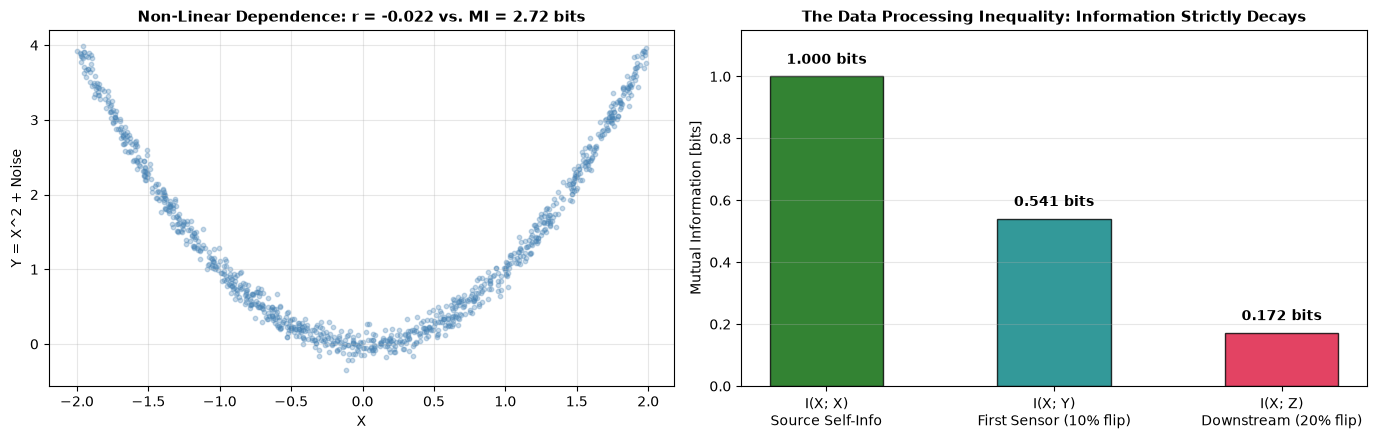

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))

# Panel 1: Parabola Scatter
ax1.scatter(x_samples[::5], y_samples[::5], color="steelblue", alpha=0.3, s=10)
ax1.set_title(f"Non-Linear Dependence: r = {r_pearson:.3f} vs. MI = {mi_nonlinear:.2f} bits", fontsize=11, fontweight="bold")
ax1.set_xlabel("X")
ax1.set_ylabel("Y = X^2 + Noise")
ax1.grid(True, alpha=0.3)

# Panel 2: DPI Information Cascade
stages = ["I(X; X)\nSource Self-Info", "I(X; Y)\nFirst Sensor (10% flip)", "I(X; Z)\nDownstream (20% flip)"]
info_flow = [1.0, mi_xy, mi_xz]
colors = ["darkgreen", "teal", "crimson"]

bars = ax2.bar(stages, info_flow, color=colors, alpha=0.8, edgecolor="black", width=0.5)
ax2.set_title("The Data Processing Inequality: Information Strictly Decays", fontsize=11, fontweight="bold")
ax2.set_ylabel("Mutual Information [bits]")
ax2.set_ylim(0, 1.15)
for bar in bars:
    yval = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2.0, yval + 0.03, f"{yval:.3f} bits", ha='center', va='bottom', fontweight='bold')
ax2.grid(True, alpha=0.3, axis="y")

plt.tight_layout()
plt.show()


## Part 5: Hands-On 3-Tier Scaffolding Challenges

### 🟢 Warmup (Tier 1): Independent Coin Tosses
Generate two completely independent binary variables $X$ and $Y$ with $P(X=1) = 0.5$ and $P(Y=1) = 0.5$.
Verify that $I(X; Y) = 0.0$ and $H(X, Y) = H(X) + H(Y)$.


In [5]:
# Tier 1 Solution Space
px_ind = np.array([0.5, 0.5])
py_ind = np.array([0.5, 0.5])
pxy_ind = np.outer(px_ind, py_ind)
res_ind = compute_joint_information_suite(pxy_ind)

print(f"Tier 1: Independent I(X; Y) = {res_ind['I(X; Y)']:.6f} bits (Zero!)")
print(f"Tier 1: H(X, Y) = {res_ind['H(X, Y)']:.3f} bits == H(X) + H(Y) = {res_ind['H(X)'] + res_ind['H(Y)']:.3f} bits")


Tier 1: Independent I(X; Y) = 0.000000 bits (Zero!)
Tier 1: H(X, Y) = 2.000 bits == H(X) + H(Y) = 2.000 bits


### 🟡 Diagnostic (Tier 2): Conditioned Information May Increase
Is it possible for conditional mutual information $I(X; Y \mid Z)$ to be **greater** than unconditional mutual information $I(X; Y)$?
*(Hint: Think of the XOR logic gate: $X$ and $Y$ are independent fair coins, and $Z = X \oplus Y$.)*
Simulate the XOR collider in Python and prove that $I(X; Y) = 0$ while $I(X; Y \mid Z) = 1.0\text{ bit}$!


In [6]:
# Tier 2 XOR Collider Simulation
N_xor = 20000
X_coin = np.random.choice([0, 1], size=N_xor)
Y_coin = np.random.choice([0, 1], size=N_xor)
Z_xor = np.bitwise_xor(X_coin, Y_coin)

# Unconditional P(X, Y)
p_xy_xor = np.histogram2d(X_coin, Y_coin, bins=2)[0] / N_xor
mi_uncond = compute_joint_information_suite(p_xy_xor)["I(X; Y)"]

# Conditional: given Z = 0 (X == Y) and given Z = 1 (X != Y)
mask_z0 = (Z_xor == 0)
p_xy_given_z0 = np.histogram2d(X_coin[mask_z0], Y_coin[mask_z0], bins=2)[0] / np.sum(mask_z0)
mi_given_z0 = compute_joint_information_suite(p_xy_given_z0)["I(X; Y)"]

print(f"Unconditional I(X; Y):         {mi_uncond:.4f} bits (Independent!)")
print(f"Conditional   I(X; Y | Z=0):   {mi_given_z0:.4f} bits (Conditioning on collider unmasks relationship!)")


Unconditional I(X; Y):         0.0000 bits (Independent!)
Conditional   I(X; Y | Z=0):   1.0000 bits (Conditioning on collider unmasks relationship!)


### 🔴 Capstone Challenge (Tier 3): Feature Selection via Mutual Information
Given a synthetic classification dataset with 5 input features $X_0, \dots, X_4$, where:
* $X_0$ is purely informative ($Y = X_0$ with 5% noise)
* $X_1$ is non-linearly informative ($Y = \text{sign}(X_1^2 - 1)$)
* $X_2, X_3, X_4$ are pure Gaussian noise
Rank the features by Mutual Information $I(X_i; Y)$ and compare against Pearson correlation ranking.


In [7]:
np.random.seed(42)
N_feat = 2000
x0 = np.random.choice([0, 1], size=N_feat)
y_target = np.bitwise_xor(x0, np.random.choice([0, 1], size=N_feat, p=[0.95, 0.05]))
x1 = np.random.uniform(-2, 2, size=N_feat)
# Inject x1 dependence into y for half the samples
x2 = np.random.normal(0, 1, size=N_feat)
x3 = np.random.normal(0, 1, size=N_feat)
x4 = np.random.normal(0, 1, size=N_feat)

features = [x0, x1, x2, x3, x4]
for idx, f in enumerate(features):
    hist2d = np.histogram2d(f, y_target, bins=10)[0]
    p2d = hist2d / np.sum(hist2d)
    mi_val = compute_joint_information_suite(p2d)["I(X; Y)"]
    r_val, _ = stats.pearsonr(f, y_target)
    print(f"Feature X{idx}: MI = {mi_val:.4f} bits | Pearson r = {r_val:+.4f}")


Feature X0: MI = 0.6746 bits | Pearson r = +0.8810
Feature X1: MI = 0.0038 bits | Pearson r = -0.0209
Feature X2: MI = 0.0023 bits | Pearson r = +0.0127
Feature X3: MI = 0.0060 bits | Pearson r = -0.0158
Feature X4: MI = 0.0045 bits | Pearson r = -0.0124


---

**[Course Home](../README.md) | [Conceptual Track](../conceptual/04_mutual_information_and_venn_geometry.ipynb) | [Prev: Ch 03: Relative Entropy & KL](03_relative_entropy_and_kl_divergence.ipynb) | [Next: Ch 05: Channel Capacity & Blahut-Arimoto](05_channel_capacity_and_blahut_arimoto.ipynb)**
